# The latent reservoir: a toy two-layer model

**Purpose.** A teaching and research notebook for M1 (fold in $\Pi$) and M2 (policy-only suppression reactivates; policy plus culture drains). It is a *mean-field toy*: one well-mixed community, two numbers, no network. Its job is to make the reservoir claim precise enough to be wrong.

**Route through the notebook**

| Part | Question | Output |
|---|---|---|
| 1 | What is a fold, geometrically? | ball on a tilting landscape, saddle-node, hysteresis in 1D |
| 2 | What is the reservoir model, term by term? | equations, nondimensionalisation, fast-slow phase plane |
| 3 | Does the model have a fold in $\Pi$? (M1) | bifurcation diagram, hysteresis loop, the $(\Pi, E)$ wedge |
| 4 | What happens after a shock and two interventions? (M2) | time series, critical policy duration, policy x culture map |
| 5 | What does universality predict near the fold? | recovery time $\propto$ (distance)$^{-1/2}$, checked numerically |
| 6 | What is assumption and what is testable? | table, and three ways this could be wrong |

Every parameter value here is chosen for illustration, not estimated. Section 6 says which ones data could pin down.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, minimize_scalar

# Palette: fixed categorical order (validated for CVD separation on the light surface).
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "font.size": 11, "axes.titlesize": 12, "legend.frameon": False, "figure.dpi": 110,
})

## Part 1. A ball on a tilting landscape

### Start with something physical

Put a marble in a bowl with two dips, like an egg box with two cups. Wherever you drop it, it rolls to the bottom of the nearest cup and stays. Now slowly tilt the egg box. The cup the marble sits in gets shallower. At some exact tilt, the cup stops being a cup at all: its bottom and the lip beside it merge into a flat ledge, and the marble rolls, suddenly, into the other cup.

Two features of that story are the whole point of this notebook:

1. **A smooth cause gives a sudden effect.** The tilt changed gradually; the marble's position jumped.
2. **Undoing the cause does not undo the effect.** Tilt the box back to where it was just before the jump and the marble stays in the new cup. You have to tilt *much* further the other way to get it back. That gap is **hysteresis**.

The reservoir argument is a claim that online punitiveness behaves like the marble: shocks tilt the landscape, the community jumps, and returning conditions to "normal" does not return the community to normal.

### The same thing as an equation

Let $u$ be the marble's position and $V(u)$ the landscape height. In thick syrup (no momentum, the ball just slides downhill at a speed set by the slope), the motion is

$$\frac{du}{dt} = -V'(u), \qquad V(u) = \frac{u^4}{4} - \frac{u^2}{2} - h\,u .$$

The $u^4/4 - u^2/2$ part is the two-cup egg box. The $-h u$ part is the tilt. So $\dot u = u - u^3 + h$. Equilibria are where the slope is zero ($V' = 0$); stable ones are valley bottoms ($V'' > 0$), unstable ones are hilltops ($V'' < 0$).

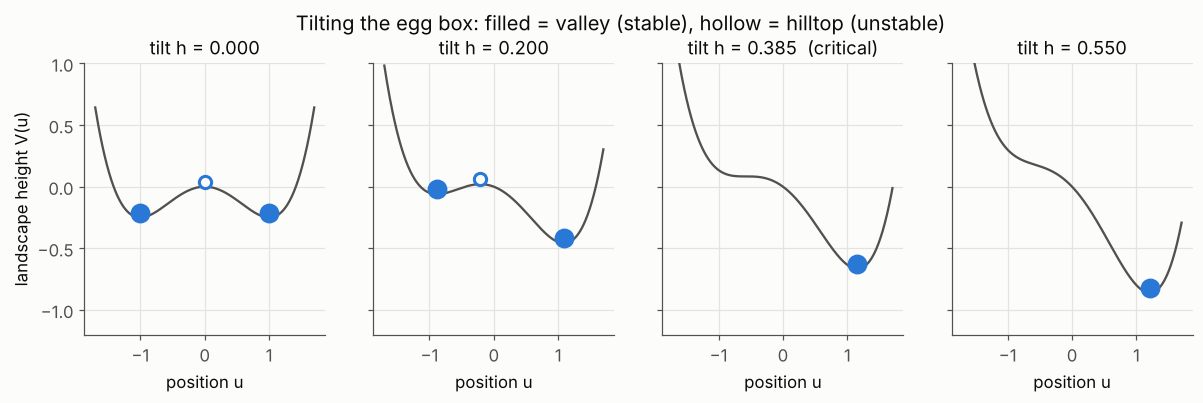

In [2]:
def V(u, h):  return u**4/4 - u**2/2 - h*u
def f1(u, h): return u - u**3 + h            # du/dt = -V'(u)

def roots_1d(h):
    r = np.roots([-1, 0, 1, h])               # -u^3 + u + h = 0
    r = np.sort(r[np.abs(r.imag) < 1e-9].real)
    return [(x, 1 - 3*x**2 < 0) for x in r]   # (position, is_stable)  since f'(u) = 1 - 3u^2

h_c = 2/(3*np.sqrt(3))                         # tilt at which a cup vanishes
u = np.linspace(-1.7, 1.7, 400)
fig, axs = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, h in zip(axs, [0.0, 0.2, h_c, 0.55]):
    ax.plot(u, V(u, h), color=INK2, lw=1.5)
    for x, stable in roots_1d(h):
        ax.plot(x, V(x, h) + 0.04, "o", ms=11 if stable else 8,
                color=BLUE if stable else SURF, mec=BLUE, mew=2)
    ax.set_title(f"tilt h = {h:.3f}" + ("  (critical)" if abs(h-h_c) < 1e-9 else ""))
    ax.set_xlabel("position u")
axs[0].set_ylabel("landscape height V(u)")
axs[0].set_ylim(-1.2, 1.0)
fig.suptitle("Tilting the egg box: filled = valley (stable), hollow = hilltop (unstable)", y=1.03)
plt.show()

Read the panels left to right. At $h = 0$ there are two valleys and a hill between them. As $h$ grows, the left valley gets shallower and the hill creeps towards it. At $h_c = 2/(3\sqrt3) \approx 0.385$ the left valley and the hill **collide and annihilate**: that collision is a **saddle-node (fold) bifurcation**. Past it only the right valley exists.

### Plotting every equilibrium against the tilt

Instead of four snapshots, plot the position of every equilibrium as a function of $h$. Valleys are solid, hilltops dashed. Then sweep $h$ slowly up and back down, letting the marble follow, and overlay its path.

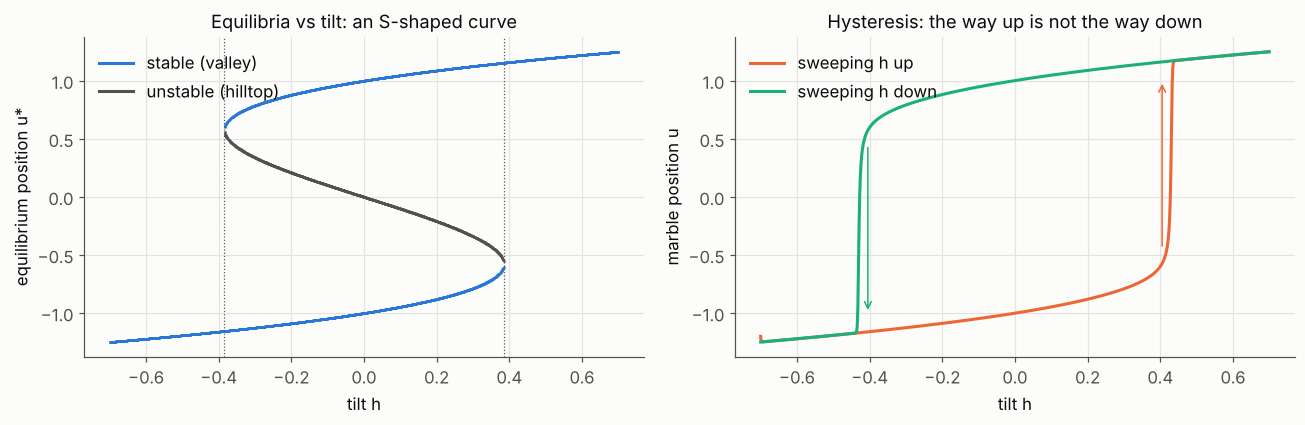

In [3]:
hs = np.linspace(-0.7, 0.7, 1401)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for h in hs:
    for x, stable in roots_1d(h):
        ax[0].plot(h, x, ".", ms=1.5, color=BLUE if stable else INK2)
ax[0].plot([], [], "-", color=BLUE, label="stable (valley)")
ax[0].plot([], [], "-", color=INK2, label="unstable (hilltop)")
ax[0].axvline(h_c, color=INK2, lw=0.8, ls=":"); ax[0].axvline(-h_c, color=INK2, lw=0.8, ls=":")
ax[0].set(xlabel="tilt h", ylabel="equilibrium position u*", title="Equilibria vs tilt: an S-shaped curve")
ax[0].legend(loc="upper left")

# quasi-static sweep: h ramps slowly up then down, marble follows
Tsweep = 400
h_of_t = lambda t: -0.7 + 1.4*(t/Tsweep) if t < Tsweep else 0.7 - 1.4*((t - Tsweep)/Tsweep)
sol = solve_ivp(lambda t, y: f1(y, h_of_t(t)), [0, 2*Tsweep], [-1.2], max_step=0.5)
up = sol.t < Tsweep
ax[1].plot([h_of_t(t) for t in sol.t[up]], sol.y[0, up], color=ORANGE, label="sweeping h up")
ax[1].plot([h_of_t(t) for t in sol.t[~up]], sol.y[0, ~up], color=AQUA, label="sweeping h down")
ax[1].annotate("", xy=(h_c+0.02, 1.0), xytext=(h_c+0.02, -0.45), arrowprops=dict(arrowstyle="->", color=ORANGE))
ax[1].annotate("", xy=(-h_c-0.02, -1.0), xytext=(-h_c-0.02, 0.45), arrowprops=dict(arrowstyle="->", color=AQUA))
ax[1].set(xlabel="tilt h", ylabel="marble position u", title="Hysteresis: the way up is not the way down")
ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

Between $-h_c$ and $+h_c$ two futures are possible and **history decides which one you get**. That middle band is the bistable region. The hilltop (dashed) is the **separatrix**: the dividing line between the two basins. A kick that pushes the marble past it changes which valley it ends in; a kick that does not, decays.

### Why the fold is universal: zoom in

Here is the reason one picture can stand for a whole family of models. Zoom into the fold point $(u_c, h_c)$ where the valley vanishes. Two things are true there by definition: the slope is zero ($f = 0$) and the valley's curvature is zero ($\partial f/\partial u = 0$, because valley and hill have merged). Taylor-expand $f$ around that point. The constant and the linear-in-$u$ terms are gone, so the first surviving terms are

$$\dot y \approx r + y^2 \quad\text{(after rescaling)}, \qquad r \propto (h - h_c), \; y \propto (u - u_c).$$

This is the **normal form** of the saddle-node. *Any* smooth system with a fold looks like this close enough to it, whatever its equations were. That is what lets the reservoir model make a prediction (Part 5) that does not depend on the particular functional forms chosen below.

The normal form tells you something measurable. For $r < 0$ the valley sits at $y^* = -\sqrt{-r}$, and the restoring "spring constant" there is $f'(y^*) = 2y^* = -2\sqrt{-r}$. So:

- **recovery rate** after a small nudge $= 2\sqrt{-r}$, which falls to zero as $r \to 0$;
- **recovery time** $\propto (-r)^{-1/2}$, which blows up.

Geometrically: as the valley flattens, the walls get gentler, so the marble rolls back more and more lazily. This is **critical slowing down**, the basis of early-warning signals (Scheffer's book). The plot below shows the exact egg-box valley near $h_c$ against the normal-form parabola.

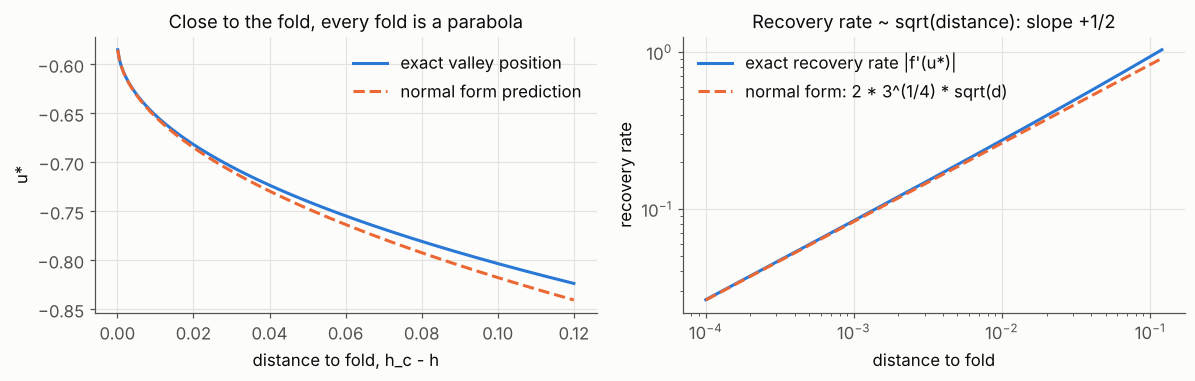

In [4]:
d = np.linspace(1e-4, 0.12, 300)              # distance below the fold, h_c - h
u_c = -1/np.sqrt(3)
exact = [min(x for x, s in roots_1d(h_c - dd) if s) for dd in d]   # the vanishing left valley
# normal form: f ~ (h - h_c) + 3^(1/2) (u - u_c)^2  -> valley at u_c - sqrt((h_c-h)/sqrt3)
nf = u_c - np.sqrt(d/np.sqrt(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(d, exact, color=BLUE, label="exact valley position")
ax[0].plot(d, nf, "--", color=ORANGE, label="normal form prediction")
ax[0].set(xlabel="distance to fold, h_c - h", ylabel="u*", title="Close to the fold, every fold is a parabola")
ax[0].legend()
rate = [abs(1 - 3*x**2) for x in exact]
ax[1].loglog(d, rate, color=BLUE, label="exact recovery rate |f'(u*)|")
ax[1].loglog(d, 2*3**0.25*np.sqrt(d), "--", color=ORANGE, label="normal form: 2 * 3^(1/4) * sqrt(d)")
ax[1].set(xlabel="distance to fold", ylabel="recovery rate", title="Recovery rate ~ sqrt(distance): slope +1/2")
ax[1].legend(); plt.tight_layout(); plt.show()

**Note on the sign of the slope.** The design doc says "recovery rate ~ sqrt(distance), log-log slope -1/2". Those two halves disagree: the *rate* scales as distance$^{+1/2}$; the *recovery time* (1/rate) scales as distance$^{-1/2}$. Part 5 plots recovery time, so the slope there is $-1/2$. Worth fixing the wording in section 10 of the doc.

## Part 2. The reservoir model

### A concrete community

Picture one community of 10,000 accounts that talk about the same things. On a given day:

- **2,400 people hold a latent punitive attitude** towards some out-group: "they did wrong, so they deserve harm or exclusion". Most of the time they keep it to themselves. That is the reservoir, $a = 0.24$.
- **600 of them post something punitive** today. That is expression, $x = 0.06$.

Why only a quarter of the holders? Because expressing it is socially risky when you think few others agree, and socially rewarded when you think many do (Kuran's preference falsification; Granovetter-style thresholds). And expression is *what other people see*. Seeing rewarded punitive posts slowly recruits new holders. Meanwhile repair (an apology accepted, a conversation that humanises, simply time and contact) slowly drains holders back out.

So there are two layers moving at very different speeds:

| Layer | Symbol | What it is | Speed |
|---|---|---|---|
| Expression | $x$ | fraction posting punitively | fast (hours to days) |
| Attitude (reservoir) | $a$ | fraction holding the attitude | slow (months to years) |

Both are fractions of the whole population, so $0 \le x \le a \le 1$ (you cannot express an attitude you do not hold, in this toy).

### The equations, term by term

**Fast layer: expression.**
$$\tau\,\frac{dx}{dt} = \underbrace{a\,P(a + E)}_{\text{holders who choose to speak}} \;-\; \underbrace{(1 + s)\,x}_{\text{posts fading or removed}}$$

- $a\,P(a+E)$: of the $a$ holders, a fraction $P$ voices it. $P$ depends on how widespread the attitude *seems* ($a$) plus an elite cue $E$ that licenses it ("our leaders are saying it, so I can").
- $P(u) = p_0 + (1 - p_0)\dfrac{u^n}{u^n + \theta^n}$. A floor $p_0$ of unconditional expressers (people who post regardless) plus a threshold switch: once the perceived share passes about $\theta$, speaking becomes rewarded rather than risky, and most holders speak. The Hill exponent $n$ sets how sharp the switch is. **This threshold is the only source of nonlinearity, and so the only reason a fold can exist.**
- $x$: expression decays on its own (posts scroll away, anger fades) at rate $1/\tau$.
- $s\,x$: policy suppression (moderation, down-ranking) removes extra expression at rate $s/\tau$. It touches $x$ only.

**Slow layer: the reservoir.**
$$\frac{da}{dt} = \underbrace{\beta\,x\,(1 - a)}_{\text{recruitment by rewarded expression}} + \underbrace{\eta'\,(1 - a)}_{\text{background adoption}} - \underbrace{\kappa\,a}_{\text{repair}}$$

- $\beta x (1-a)$: non-holders $(1-a)$ meet punitive expression $x$ and some adopt the attitude. $\beta$ bundles exposure and *reward*: expression that earns approval is more persuasive (H1 is the empirical version of this term).
- $\eta'(1-a)$: a small trickle of adoption not driven by in-community expression (offline grievance, outside media). It keeps the calm state slightly above zero.
- $\kappa a$: repair drains holders at rate $\kappa$ (Gottman's repair attempts, deep canvassing, reintegrative shaming). Culture works by raising $\kappa$.

### Nondimensionalise: why bother?

The dimensional model has seven knobs: $\tau, \beta, \eta', \kappa, \theta, n, p_0$. But the system cannot "know" what units you measure time in. Only *ratios* of rates can matter (Buckingham $\pi$ theorem). Measure time in units of the baseline repair time, $T = \kappa_0 t$, and three ratios fall out:

$$\varepsilon = \kappa_0 \tau \;\;\text{(fast time / slow time)}, \qquad \Pi = \frac{\beta}{\kappa_0} \;\;\text{(punitive spread / repair)}, \qquad \eta = \frac{\eta'}{\kappa_0}.$$

Write $\rho = \kappa/\kappa_0$ for a culture intervention that multiplies repair. The model becomes

$$\boxed{\;\varepsilon\,\frac{dx}{dT} = a\,P(a+E) - (1+s)\,x, \qquad \frac{da}{dT} = \Pi\,x\,(1-a) + \eta\,(1-a) - \rho\,a\;}$$

Why this is worth doing:

1. **Fewer knobs.** Doubling both spread and repair changes nothing about *where* the system ends up; only $\Pi$ does. That is why $\Pi$ is the natural control parameter for M1.
2. **It separates what equilibria can tell you from what dynamics can tell you.** Set the time derivatives to zero: $\varepsilon$ vanishes. Equilibria depend on $\Pi$ (and $\eta, \theta, n, p_0, E, s, \rho$) but never on $\varepsilon$. Cross-sectional data can at best identify $\Pi$; timescales need time series.
3. **$\varepsilon \ll 1$ licenses a simplification.** If expression relaxes much faster than attitudes, $x$ is always close to its target, $x \approx x_\infty(a) = a P(a+E)/(1+s)$, and the 2D model collapses to one equation in $a$ on the **slow manifold**:
$$\frac{da}{dT} = g(a) = \Pi\,x_\infty(a)\,(1-a) + \eta(1-a) - \rho a.$$
That is a 1D system like the egg box, so everything in Part 1 applies to it.

The cell below fixes illustrative parameter values.

In [5]:
# Illustrative parameters (dimensionless). None are estimated from data.
theta = 0.30   # perceived-share threshold at which speaking becomes rewarded
n     = 4      # sharpness of that threshold
p0    = 0.20   # unconditional expressers: fraction of holders who speak regardless
eta   = 0.01   # background adoption (relative to baseline repair)
eps   = 0.02   # fast/slow timescale ratio: expression relaxes 50x faster than attitudes
PI0   = 3.0    # baseline punitive spread / repair (chosen inside the bistable band, see Part 3)

def P(u):
    u = np.maximum(u, 0.0)
    return p0 + (1 - p0) * u**n / (u**n + theta**n)

def dP(u):
    u = np.maximum(u, 0.0)
    return (1 - p0) * n * theta**n * u**(n-1) / (u**n + theta**n)**2

def x_inf(a, E=0.0, s=0.0):
    return a * P(a + E) / (1 + s)

def g(a, Pi, E=0.0, s=0.0, rho=1.0):
    "Reduced slow-manifold dynamics da/dT."
    return Pi * x_inf(a, E, s) * (1 - a) + eta * (1 - a) - rho * a

def rhs(T, y, Pi, E=0.0, s=0.0, rho=1.0):
    "Full two-layer model. y = (x, a). Parameters may be callables of T."
    x, a = y
    Pi_, E_, s_, rho_ = [p(T) if callable(p) else p for p in (Pi, E, s, rho)]
    dx = (a * P(a + E_) - (1 + s_) * x) / eps
    da = Pi_ * x * (1 - a) + eta * (1 - a) - rho_ * a
    return [dx, da]

def jacobian(x, a, Pi, E=0.0, s=0.0, rho=1.0):
    d_xinf_num = P(a + E) + a * dP(a + E)            # d/da [a P(a+E)]
    return np.array([[-(1 + s) / eps, d_xinf_num / eps],
                     [Pi * (1 - a), -Pi * x - eta - rho]])

def equilibria(Pi, E=0.0, s=0.0, rho=1.0, grid=4001):
    "All equilibria by root-finding on a fine grid of a (bracket sign changes, then Brent)."
    A = np.linspace(0, 1, grid); G = g(A, Pi, E, s, rho)
    out = []
    for i in np.where(np.sign(G[:-1]) != np.sign(G[1:]))[0]:
        a = brentq(g, A[i], A[i+1], args=(Pi, E, s, rho), xtol=1e-13)
        x = x_inf(a, E, s)
        lam = np.linalg.eigvals(jacobian(x, a, Pi, E, s, rho))
        out.append(dict(a=a, x=x, stable=bool(np.all(lam.real < 0)), lam=lam))
    return out

for e in equilibria(PI0):
    print(f"a* = {e['a']:.3f}  x* = {e['x']:.3f}  {'stable' if e['stable'] else 'UNSTABLE'}"
          f"  eigenvalues = {np.round(e['lam'].real, 3)}")

a* = 0.024  x* = 0.005  stable  eigenvalues = [-50.591  -0.433]
a* = 0.236  x* = 0.100  UNSTABLE  eigenvalues = [-52.388   1.078]
a* = 0.657  x* = 0.635  stable  eigenvalues = [-51.167  -1.748]


At $\Pi = 3$ there are three equilibria: a calm state ($a \approx 0.02$), a punitive state ($a \approx 0.66$), and an unstable one between them ($a \approx 0.24$) which is the separatrix. Each has two eigenvalues: one around $-50$ (the fast layer snapping back, $\approx -1/\varepsilon$) and one of order 1 (the slow reservoir). The slow one decides stability.

### The reservoir as a landscape

Because the reduced model is 1D, it has a potential, $V(a) = -\int g\,da$, exactly like the egg box. Here it is for three values of $\Pi$.

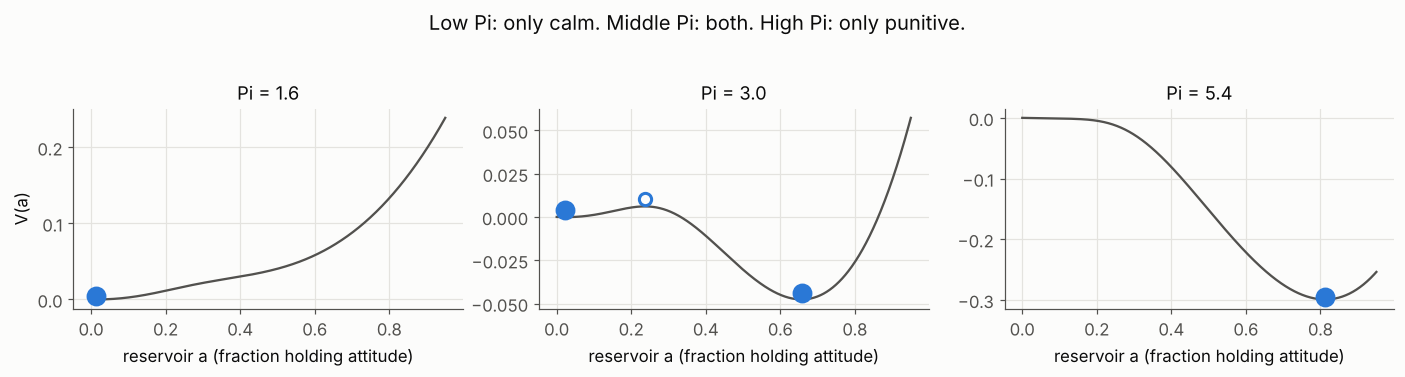

In [6]:
A = np.linspace(0, 0.95, 800)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, Pi in zip(axs, [1.6, PI0, 5.4]):
    Vp = -np.concatenate([[0], np.cumsum(0.5*(g(A[1:], Pi) + g(A[:-1], Pi)) * np.diff(A))])
    ax.plot(A, Vp, color=INK2, lw=1.5)
    for e in equilibria(Pi):
        j = np.argmin(abs(A - e["a"]))
        ax.plot(e["a"], Vp[j] + 0.004, "o", ms=11 if e["stable"] else 8,
                color=BLUE if e["stable"] else SURF, mec=BLUE, mew=2)
    ax.set(title=f"Pi = {Pi}", xlabel="reservoir a (fraction holding attitude)")
axs[0].set_ylabel("V(a)")
fig.suptitle("Low Pi: only calm. Middle Pi: both. High Pi: only punitive.", y=1.03)
plt.tight_layout(); plt.show()

### The fast-slow picture in the $(a, x)$ plane

The 1D reduction is an approximation. To see what the full two-layer model does, draw the plane with the reservoir $a$ across and expression $x$ up. Two curves organise everything:

- **$x$-nullcline** (where $\dot x = 0$): $x = a P(a+E)/(1+s)$. Because $\varepsilon$ is small, trajectories shoot *vertically* onto this curve almost instantly, then crawl along it. It is the slow manifold.
- **$a$-nullcline** (where $\dot a = 0$): $x = \dfrac{\rho a - \eta(1-a)}{\Pi(1-a)}$.

Equilibria are where they cross. The right panel switches policy on ($s = 3$): the $x$-nullcline is pushed down, the punitive crossing disappears, and trajectories are forced downward. But notice where they go while policy is on: they move left (the reservoir drains) only at the slow crawl speed. **Policy moves the fast variable instantly and the slow one only slowly.** That geometric fact is M2.

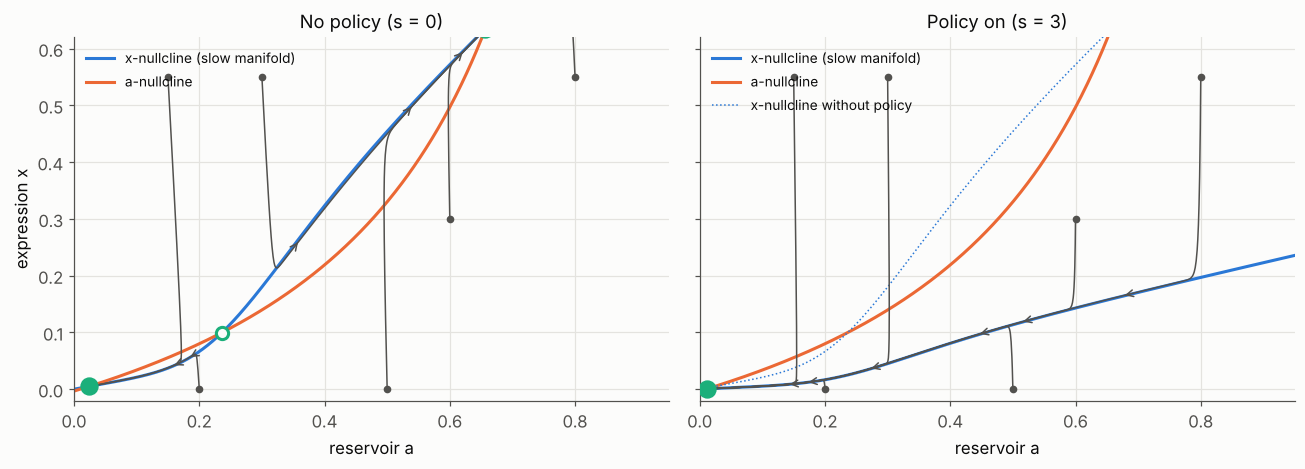

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
A = np.linspace(0.001, 0.95, 600)
for ax, s, ttl in [(axs[0], 0.0, "No policy (s = 0)"), (axs[1], 3.0, "Policy on (s = 3)")]:
    ax.plot(A, x_inf(A, s=s), color=BLUE, label="x-nullcline (slow manifold)")
    an = (A - eta*(1 - A)) / (PI0 * (1 - A))
    ax.plot(A, an, color=ORANGE, label="a-nullcline")
    if s > 0:
        ax.plot(A, x_inf(A), color=BLUE, lw=1, ls=":", label="x-nullcline without policy")
    for x0, a0 in [(0.55, 0.15), (0.55, 0.30), (0.55, 0.8), (0.0, 0.5), (0.0, 0.2), (0.3, 0.6)]:
        sol = solve_ivp(rhs, [0, 6], [x0, a0], args=(PI0, 0.0, s), method="LSODA", max_step=0.01)
        ax.plot(sol.y[1], sol.y[0], color=INK2, lw=1)
        ax.plot(a0, x0, "o", ms=4, color=INK2)
        k = min(len(sol.t)-1, 40)
        ax.annotate("", xy=(sol.y[1][k+1], sol.y[0][k+1]), xytext=(sol.y[1][k], sol.y[0][k]),
                    arrowprops=dict(arrowstyle="->", color=INK2))
    for e in equilibria(PI0, s=s):
        ax.plot(e["a"], e["x"], "o", ms=10 if e["stable"] else 8,
                color=AQUA if e["stable"] else SURF, mec=AQUA, mew=2, zorder=5)
    ax.set(xlim=(0, 0.95), ylim=(-0.02, 0.62), xlabel="reservoir a", title=ttl)
axs[0].set_ylabel("expression x"); axs[0].legend(loc="upper left", fontsize=9); axs[1].legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

## Part 3. The fold in $\Pi$ (M1)

### Numerical continuation by root-finding sweep

For each value of $\Pi$ on a fine grid, find *every* equilibrium (bracket sign changes of $g$ on a grid of $a$, then polish with Brent's method) and classify each by the eigenvalues of the full 2D Jacobian. That is a brute-force continuation: crude but impossible to fool into missing a branch, which is the right trade-off for a 1D slow manifold.

A cross-check comes for free here. $\Pi$ enters $g$ linearly, so $g = 0$ can be solved for $\Pi$ *as a function of* $a$:
$$\Pi(a) = \frac{\rho a - \eta(1-a)}{(1-a)\,x_\infty(a)} .$$
Tracing $a$ from 0 to 1 draws the whole S-curve exactly, and the folds are the turning points of $\Pi(a)$. (This trick is special to this toy; for the ABM you would need pseudo-arclength continuation, e.g. via a package such as PyDSTool or BifurcationKit.)

In [8]:
def Pi_of_a(a, E=0.0, s=0.0, rho=1.0):
    return (rho*a - eta*(1 - a)) / ((1 - a) * x_inf(a, E, s))

def folds(E=0.0, s=0.0, rho=1.0):
    "Turning points of Pi(a): (Pi_lower, a_lower), (Pi_upper, a_upper). None if no fold."
    A = np.linspace(eta/(rho+eta) + 1e-4, 0.995, 20000)
    Pa = Pi_of_a(A, E, s, rho); d = np.diff(Pa)
    idx = np.where(np.sign(d[1:]) != np.sign(d[:-1]))[0] + 1
    if len(idx) != 2: return None
    out = []
    for i, sign in zip(idx, [-1.0, +1.0]):   # local max of Pi(a) (upper fold) comes first in a, then local min
        res = minimize_scalar(lambda a: sign * Pi_of_a(a, E, s, rho),
                              bounds=(A[i-5], A[i+5]), method="bounded", options=dict(xatol=1e-12))
        out.append((Pi_of_a(res.x, E, s, rho), res.x))
    (Pu, au), (Pl, al) = out
    return dict(Pi_lower=Pl, a_lower=al, Pi_upper=Pu, a_upper=au)

F = folds()
print(f"lower fold (punitive state vanishes): Pi = {F['Pi_lower']:.4f} at a = {F['a_lower']:.3f}")
print(f"upper fold (calm state vanishes):     Pi = {F['Pi_upper']:.4f} at a = {F['a_upper']:.3f}")

Pis = np.linspace(0.5, 7, 1301)
branch = [(Pi, e["a"], e["stable"]) for Pi in Pis for e in equilibria(Pi)]

lower fold (punitive state vanishes): Pi = 2.0322 at a = 0.404
upper fold (calm state vanishes):     Pi = 4.8251 at a = 0.105


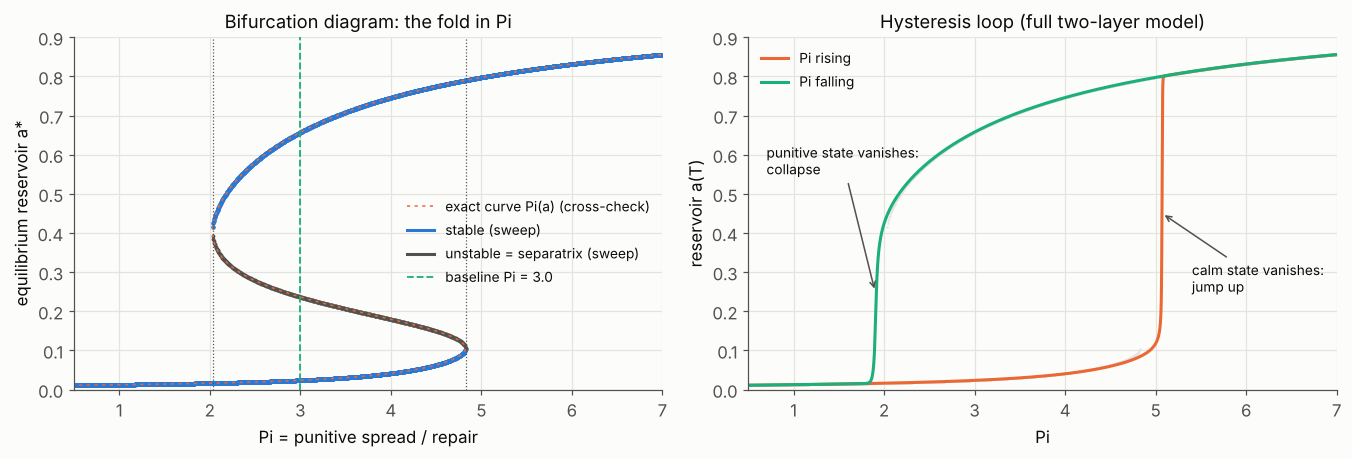

Bistable band: 2.03 < Pi < 4.83  (width ratio 2.37)


In [9]:
# Hysteresis: sweep Pi slowly up then down in the FULL 2D model and let the state follow.
Tramp = 600.0
Pi_lo, Pi_hi = 0.5, 7.0
Pi_t = lambda T: Pi_lo + (Pi_hi - Pi_lo) * (T/Tramp) if T < Tramp else Pi_hi - (Pi_hi - Pi_lo) * ((T - Tramp)/Tramp)
e0 = equilibria(Pi_lo)[0]
sol = solve_ivp(rhs, [0, 2*Tramp], [e0["x"], e0["a"]], args=(Pi_t,), method="LSODA", max_step=0.2)
PiT = np.array([Pi_t(T) for T in sol.t]); up = sol.t < Tramp

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
B = np.array([(p, a) for p, a, s in branch if s]); U = np.array([(p, a) for p, a, s in branch if not s])
ax[0].plot(B[:, 0], B[:, 1], ".", ms=4, color=BLUE)
ax[0].plot(U[:, 0], U[:, 1], ".", ms=3, color=INK2)
Aex = np.linspace(eta/(1+eta) + 1e-4, 0.97, 3000)
ax[0].plot(Pi_of_a(Aex), Aex, color=ORANGE, lw=1, ls=(0, (2, 3)), label="exact curve Pi(a) (cross-check)")
ax[0].plot([], [], "-", color=BLUE, label="stable (sweep)"); ax[0].plot([], [], "-", color=INK2, label="unstable = separatrix (sweep)")
for k in ("Pi_lower", "Pi_upper"): ax[0].axvline(F[k], color=INK2, lw=0.8, ls=":")
ax[0].axvline(PI0, color=AQUA, lw=1.2, ls="--", label=f"baseline Pi = {PI0}")
ax[0].set(xlim=(0.5, 7), ylim=(0, 0.9), xlabel="Pi = punitive spread / repair", ylabel="equilibrium reservoir a*",
          title="Bifurcation diagram: the fold in Pi")
ax[0].legend(fontsize=9, loc="center right", bbox_to_anchor=(1.0, 0.42))

ax[1].plot(B[:, 0], B[:, 1], ".", ms=1, color=GRID)
ax[1].plot(PiT[up], sol.y[1, up], color=ORANGE, label="Pi rising")
ax[1].plot(PiT[~up], sol.y[1, ~up], color=AQUA, label="Pi falling")
ax[1].annotate("calm state vanishes:\njump up", xy=(5.07, 0.45), xytext=(5.4, 0.25),
               arrowprops=dict(arrowstyle="->", color=INK2), fontsize=9)
ax[1].annotate("punitive state vanishes:\ncollapse", xy=(1.9, 0.25), xytext=(0.7, 0.55),
               arrowprops=dict(arrowstyle="->", color=INK2), fontsize=9)
ax[1].set(xlim=(0.5, 7), ylim=(0, 0.9), xlabel="Pi", ylabel="reservoir a(T)", title="Hysteresis loop (full two-layer model)")
ax[1].legend(fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()
print(f"Bistable band: {F['Pi_lower']:.2f} < Pi < {F['Pi_upper']:.2f}  (width ratio {F['Pi_upper']/F['Pi_lower']:.2f})")

**Reading it.** Raise punitive spread relative to repair and the community stays calm until $\Pi \approx 4.8$, then jumps to a high reservoir. Lower $\Pi$ again and it does not come back at 4.8: it stays punitive until $\Pi \approx 2.0$. Between those, the state depends on history. In the doc's language, the **upper fold** is the forward tipping point and the **lower fold** is RQ2's reverse tipping point: repair has to push $\Pi$ well below where the trouble started.

The dashed orange line (exact $\Pi(a)$) sits on top of the sweep, which checks the root-finder. In the right panel the jumps happen slightly *past* each fold (about 5.07 and 1.9 rather than 4.83 and 2.03): because $\Pi$ is ramped at a finite speed and recovery is slow near a fold, the state lags. That lag is itself a symptom of Part 5's critical slowing down, and real drifts will show it too.

### The second control: elite cues $E$ and the wedge

$E$ tilts the landscape too (it lowers the perceived-share threshold). Tracking both folds as $E$ varies gives the bistable region in the $(\Pi, E)$ plane. Where the two fold curves meet, the S-curve straightens out: that point is a **cusp**. This is the shape the doc means by "fold/cusp in $(\Pi, E)$".

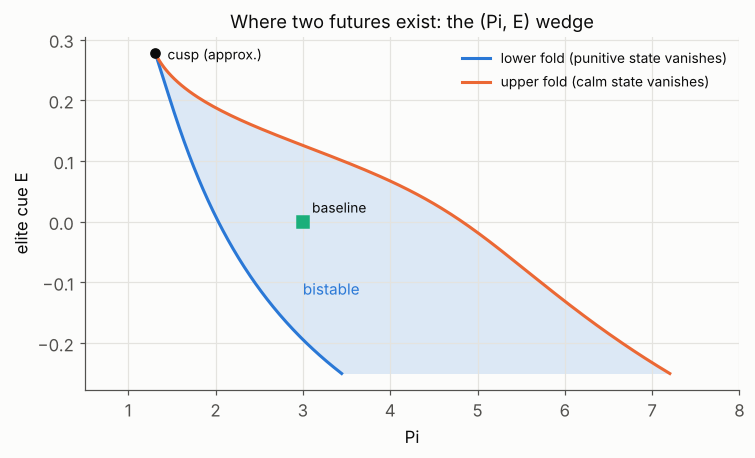

Folds disappear at about E = 0.277, Pi = 1.31


In [10]:
Es = np.linspace(-0.25, 0.30, 221)
FL = [(E, folds(E=E)) for E in Es]
FL = [(E, f) for E, f in FL if f is not None]
Ev = np.array([E for E, _ in FL]); Pl = np.array([f["Pi_lower"] for _, f in FL]); Pu = np.array([f["Pi_upper"] for _, f in FL])
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.fill_betweenx(Ev, Pl, Pu, color=BLUE, alpha=0.15, lw=0)
ax.plot(Pl, Ev, color=BLUE, label="lower fold (punitive state vanishes)")
ax.plot(Pu, Ev, color=ORANGE, label="upper fold (calm state vanishes)")
ax.plot(Pl[-1], Ev[-1], "o", color=INK, ms=6); ax.annotate("cusp (approx.)", (Pl[-1], Ev[-1]), xytext=(8, -4), textcoords="offset points", fontsize=9)
ax.plot(PI0, 0, "s", color=AQUA, ms=8); ax.annotate("baseline", (PI0, 0), xytext=(6, 6), textcoords="offset points", fontsize=9)
ax.text(3.0, -0.12, "bistable", color=BLUE, fontsize=10)
ax.set(xlabel="Pi", ylabel="elite cue E", title="Where two futures exist: the (Pi, E) wedge", xlim=(0.5, 8))
ax.legend(fontsize=9, loc="upper right"); plt.tight_layout(); plt.show()
print(f"Folds disappear at about E = {Ev[-1]:.3f}, Pi = {Pl[-1]:.2f}")

A sustained positive cue (a **tilt**, in section 8's vocabulary) shrinks the bistable band and drags the upper fold down to lower $\Pi$, so less reward is needed to tip. Negative $E$ (elites de-licensing punitiveness) widens the band and makes the calm state more robust. A **kick** is a brief pulse in $E$: it temporarily removes the calm valley, which is what Part 4 simulates.

## Part 4. Shock, then two interventions (M2)

### The scenario

Start at baseline $\Pi = 3$ in the calm state. Then:

1. **Kick** at $T = 3$ to $5$: elite cue $E = 0.4$ (a war, a killing, a scandal blamed on the out-group). With the cue on, the calm valley does not exist, so the reservoir fills.
2. Cue removed at $T = 5$. Has the reservoir passed the separatrix ($a \approx 0.24$)? If so, it keeps filling on its own.
3. **Intervention window** $T = 12$ to $13.2$, then everything removed. Four arms:
   - none;
   - **policy only**: suppression $s = 3$ (expression removed four times faster than it fades);
   - **policy + culture**: $s = 3$ and repair raised $\rho = 2.5$;
   - **culture only**: $\rho = 2.5$, for comparison.

Time is in units of baseline repair time $1/\kappa_0$. If that is a few years, the window is a few years too: deliberately about one electoral cycle.

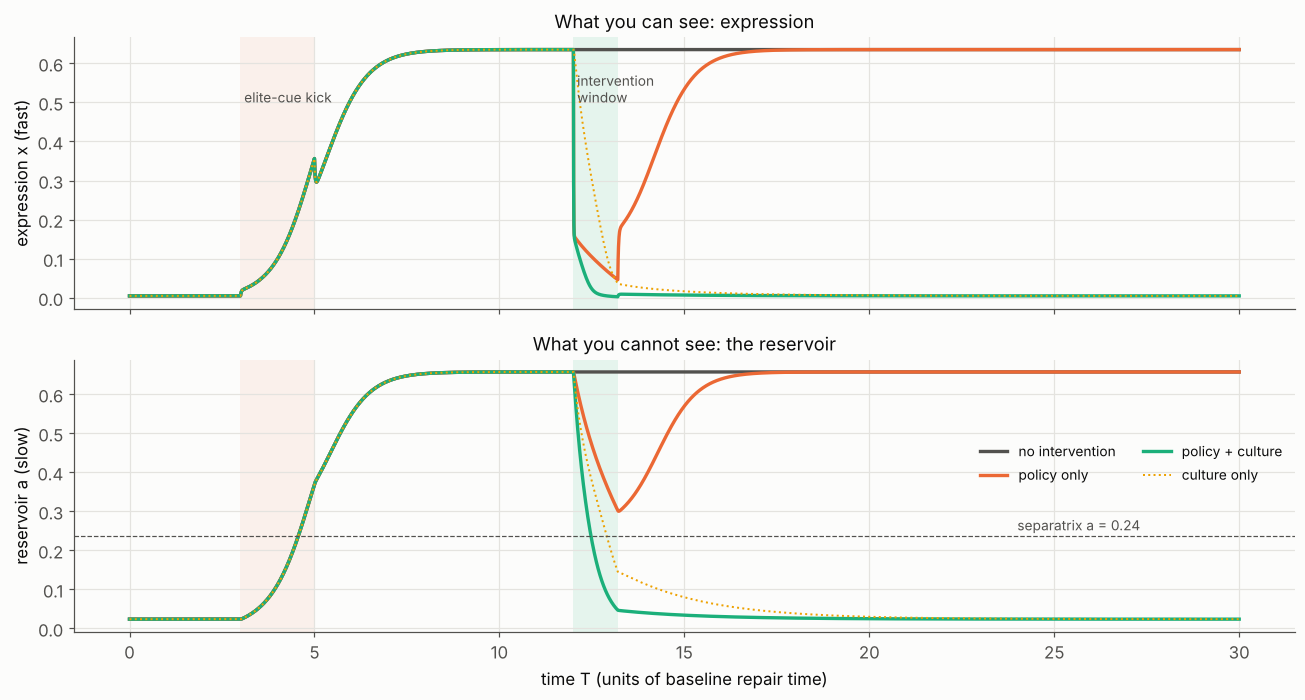

no intervention    a at end of window = 0.657   x at end of window = 0.635   final a = 0.657
policy only        a at end of window = 0.302   x at end of window = 0.046   final a = 0.657
policy + culture   a at end of window = 0.047   x at end of window = 0.002   final a = 0.024
culture only       a at end of window = 0.145   x at end of window = 0.037   final a = 0.024


In [11]:
KICK, E_KICK = (3.0, 5.0), 0.4
WIN = (12.0, 13.2)
S_POL, RHO_CUL = 3.0, 2.5
box = lambda w, val, base: (lambda T: val if w[0] <= T < w[1] else base)

arms = {
    "no intervention":   dict(s=0.0,   rho=1.0),
    "policy only":       dict(s=S_POL, rho=1.0),
    "policy + culture":  dict(s=S_POL, rho=RHO_CUL),
    "culture only":      dict(s=0.0,   rho=RHO_CUL),
}
colours = dict(zip(arms, [INK2, ORANGE, AQUA, YELLOW]))
calm = equilibria(PI0)[0]
y0 = [calm["x"], calm["a"]]
a_sep = equilibria(PI0)[1]["a"]

runs = {}
for name, p in arms.items():
    sol = solve_ivp(rhs, [0, 30], y0, method="LSODA", max_step=0.01,
                    args=(PI0, box(KICK, E_KICK, 0.0), box(WIN, p["s"], 0.0), box(WIN, p["rho"], 1.0)))
    runs[name] = sol

fig, axs = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax in axs:
    ax.axvspan(*KICK, color=ORANGE, alpha=0.08, lw=0); ax.axvspan(*WIN, color=AQUA, alpha=0.10, lw=0)
for name, sol in runs.items():
    lw = 1.3 if name == "culture only" else 2.2
    ls = ":" if name == "culture only" else "-"
    axs[0].plot(sol.t, sol.y[0], color=colours[name], lw=lw, ls=ls, label=name)
    axs[1].plot(sol.t, sol.y[1], color=colours[name], lw=lw, ls=ls, label=name)
axs[1].axhline(a_sep, color=INK2, lw=0.8, ls="--")
axs[1].text(24, a_sep + 0.015, f"separatrix a = {a_sep:.2f}", fontsize=9, color=INK2)
axs[0].text(KICK[0] + 0.1, 0.5, "elite-cue kick", fontsize=9, color=INK2)
axs[0].text(WIN[0] + 0.1, 0.5, "intervention\nwindow", fontsize=9, color=INK2)
axs[0].set(ylabel="expression x (fast)", title="What you can see: expression")
axs[1].set(ylabel="reservoir a (slow)", xlabel="time T (units of baseline repair time)", title="What you cannot see: the reservoir")
axs[1].legend(ncol=2, fontsize=9, loc="center right", bbox_to_anchor=(1.0, 0.62))
plt.tight_layout(); plt.show()
for name, sol in runs.items():
    i = np.searchsorted(sol.t, WIN[1])
    print(f"{name:18s} a at end of window = {sol.y[1, i]:.3f}   x at end of window = {sol.y[0, i]:.3f}   final a = {sol.y[1, -1]:.3f}")

**What the plot shows**

- **The kick tips the system.** After the cue is withdrawn at $T = 5$ the reservoir has passed the separatrix and keeps filling to the punitive state. The cause is gone; the effect stays (hysteresis).
- **Policy only: visible success, then reactivation.** Expression (top) collapses the moment policy starts. Anyone measuring posts would call it a win. But the reservoir (bottom) only drains at the slow repair speed, is still above the separatrix when policy ends, and expression comes straight back. This is "visible progress outruns real attitude change".
- **Policy + culture: the reservoir drains below the separatrix** within the same window, and the calm state then holds *after both are removed*. Durable, in section 9's sense: it crossed the separatrix.
- **Culture only** ($\rho = 2.5$) also gets there here, though expression falls more slowly. So with these particular numbers the time series alone shows an **asymmetry** (policy is the weaker lever on the reservoir), not yet complementarity. The map below checks when complementarity appears.

### Why policy has a speed limit

This is the cleanest result in the toy, and it holds for any $P$. While policy is on, expression can be pushed towards zero but no lower, so recruitment $\Pi x (1-a) \ge 0$. Therefore
$$\frac{da}{dT} \;\ge\; \eta(1-a) - \rho\, a \quad\Longrightarrow\quad a(T) - a_\infty \;\ge\; (a_0 - a_\infty)\,e^{-(\rho+\eta) T}, \qquad a_\infty = \frac{\eta}{\rho + \eta}.$$
With $\rho = 1$ (policy without culture) the reservoir can drain no faster than the baseline repair rate. So there is a **minimum policy duration** to cross the separatrix,
$$D_{\min} = \frac{1}{1+\eta}\,\ln\!\frac{a_{\text{high}} - a_\infty}{a_{\text{sep}} - a_\infty},$$
however strong the suppression. Only raising $\rho$ shortens it. That is the formal content of "policy can suppress but only repair can drain". Check it numerically: sweep the policy duration for several strengths.

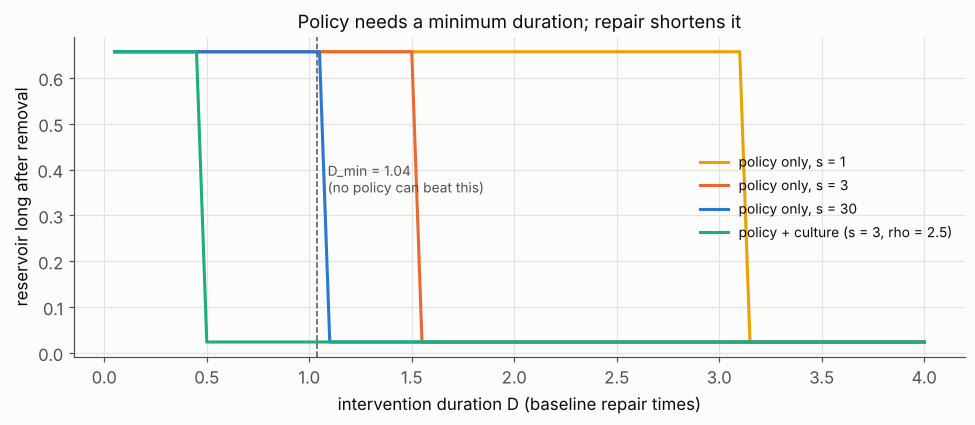

In [12]:
high = equilibria(PI0)[-1]
a_inf = eta / (1 + eta)
D_min = np.log((high["a"] - a_inf) / (a_sep - a_inf)) / (1 + eta)

def final_a(D, s, rho, Pi=PI0, start=high, Tend=40.0):
    w = (1.0, 1.0 + D)
    sol = solve_ivp(rhs, [0, Tend], [start["x"], start["a"]], method="LSODA", max_step=0.02,
                    args=(Pi, 0.0, box(w, s, 0.0), box(w, rho, 1.0)))
    return sol.y[1, -1]

Ds = np.linspace(0.05, 4.0, 80)
fig, ax = plt.subplots(figsize=(9, 4))
for s, c in [(1.0, YELLOW), (3.0, ORANGE), (30.0, BLUE)]:
    ax.plot(Ds, [final_a(D, s, 1.0) for D in Ds], color=c, label=f"policy only, s = {s:g}")
ax.plot(Ds, [final_a(D, S_POL, RHO_CUL) for D in Ds], color=AQUA, label=f"policy + culture (s = {S_POL:g}, rho = {RHO_CUL})")
ax.axvline(D_min, color=INK2, ls="--", lw=1)
ax.text(D_min + 0.05, 0.35, f"D_min = {D_min:.2f}\n(no policy can beat this)", fontsize=9, color=INK2)
ax.set(xlabel="intervention duration D (baseline repair times)", ylabel="reservoir long after removal",
       title="Policy needs a minimum duration; repair shortens it")
ax.legend(fontsize=9, loc="center right"); plt.tight_layout(); plt.show()

Even near-total suppression ($s = 30$) cannot work faster than $D_{\min} \approx 1$ repair time. If repair time is generational and electoral cycles are 4 to 5 years (section 9's timescale mismatch), policy alone is cut off before it crosses.

### Policy x culture: substitutes or complements?

Hold the window fixed at $D = 0.9$, deliberately **shorter** than $D_{\min}$ (an intervention cut off by the electoral cycle), and vary both levers. Shade where the reservoir ends **below** the separatrix after everything is removed.

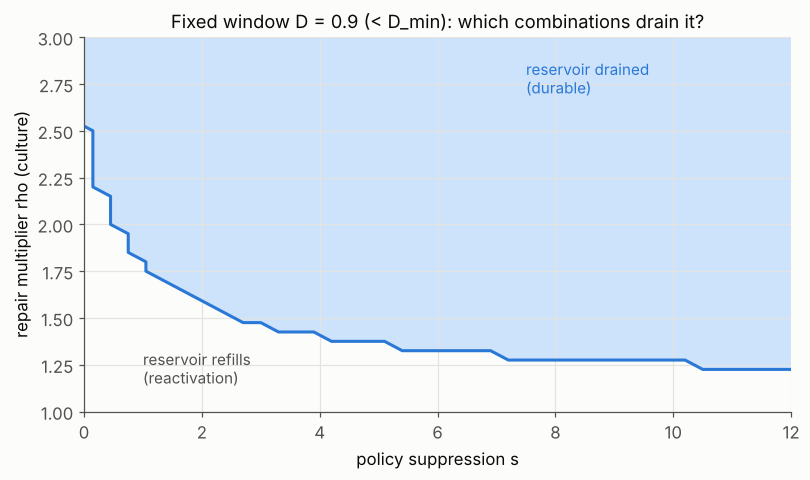

s =    0: culture needed rho >= 2.55
s =    1: culture needed rho >= 1.85
s =    3: culture needed rho >= 1.50
s =    6: culture needed rho >= 1.35
s =   12: culture needed rho >= 1.25


In [13]:
D_MAP = 0.9
S_grid = np.linspace(0, 12, 41); R_grid = np.linspace(1.0, 3.0, 41)
Z = np.array([[final_a(D_MAP, s, r) for s in S_grid] for r in R_grid])
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.contourf(S_grid, R_grid, (Z < a_sep).astype(float), levels=[-0.5, 0.5, 1.5], colors=[SURF, "#cde2fb"])
ax.contour(S_grid, R_grid, (Z < a_sep).astype(float), levels=[0.5], colors=[BLUE], linewidths=2)
ax.text(1.0, 1.15, "reservoir refills\n(reactivation)", fontsize=10, color=INK2)
ax.text(7.5, 2.7, "reservoir drained\n(durable)", fontsize=10, color=BLUE)
rho_need = [R_grid[np.argmax(Z[:, j] < a_sep)] if np.any(Z[:, j] < a_sep) else np.nan for j in range(len(S_grid))]
ax.set(xlabel="policy suppression s", ylabel="repair multiplier rho (culture)",
       title=f"Fixed window D = {D_MAP} (< D_min): which combinations drain it?")
plt.tight_layout(); plt.show()
for s_ in [0, 1, 3, 6, 12]:
    j = np.argmin(abs(S_grid - s_)); print(f"s = {s_:>4}: culture needed rho >= {rho_need[j]:.2f}")

Three regions, read along the edges:

- **Bottom edge (policy only):** never drains, however strong, because $D = 0.9 < D_{\min}$. Policy saturates.
- **Left edge (culture only):** drains only if repair is raised by about $\rho \ge 2.5$ for the whole window.
- **Interior:** with $s = 3$, $\rho \approx 1.5$ is enough; with strong policy, $\rho \approx 1.2$.

So there is a genuine **complementarity band** (roughly $1.2 \lesssim \rho \lesssim 2.5$): neither lever alone drains the reservoir within the window, both together do. Mechanism: policy cuts the inflow (recruitment), culture raises the outflow (repair), and the reservoir needs net drain to clear the separatrix before the window closes. Outside the band they behave as partial substitutes, and only culture can work alone. A sharper version of the doc's sentence would be: **policy buys time and cuts inflow; only repair raises the drain ceiling; under short windows they are complements.** Worth deciding which formulation the paper commits to.

## Part 5. The normal-form prediction near the fold

Part 1 showed that near *any* fold, recovery from a small nudge slows down as $\sqrt{\text{distance}}$. If the reservoir model is right in its *qualitative* structure (a fold exists), this must hold regardless of the specific $P$, $n$, $\theta$ chosen above. That universality is what makes it worth testing.

**Test.** Approach the upper fold from below (calm state, $\Pi \to \Pi_{\text{upper}}$), the forward tipping point that early warning would care about. At each distance $d = \Pi_{\text{upper}} - \Pi$:

1. *Linearisation:* slow eigenvalue $\lambda$ of the full 2D Jacobian at the calm equilibrium; recovery time $= 1/|\lambda|$.
2. *Simulation:* nudge the full model off the calm state, integrate, and fit the exponential decay rate of the deviation. No linear algebra involved.

Normal-form prediction: recovery time $\propto d^{-1/2}$, a straight line of slope $-1/2$ on log-log axes.

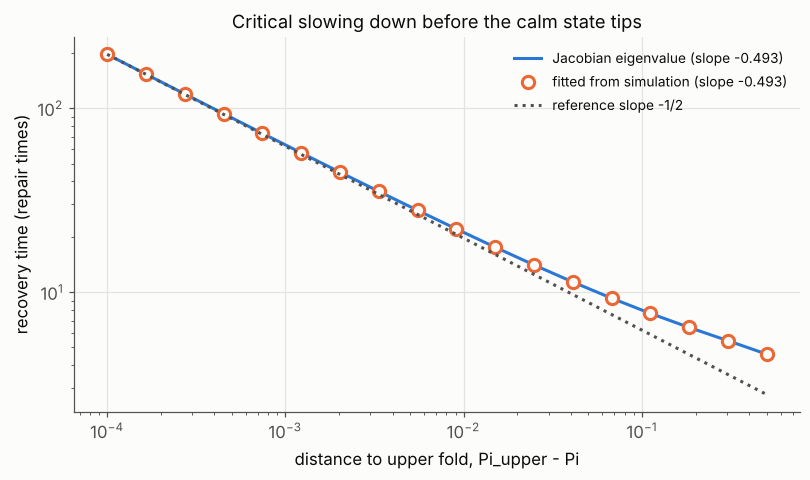

Upper fold at Pi = 4.82507. Fitted log-log slope for d < 1e-3: linearisation -0.4932, simulation -0.4932


In [14]:
Pc = F["Pi_upper"]
ds = np.logspace(-4, -0.3, 18)
t_lin, t_sim = [], []
for d in ds:
    e = equilibria(Pc - d, grid=20001)[0]                      # calm state
    lam_slow = max(np.linalg.eigvals(jacobian(e["x"], e["a"], Pc - d)).real)
    t_lin.append(-1 / lam_slow)
    # simulation: nudge a by a small fraction of the node-saddle gap (~sqrt(d)), stay linear
    delta = 0.02 * np.sqrt(d) * 0.1
    sol = solve_ivp(rhs, [0, 12 / abs(lam_slow)], [e["x"], e["a"] + delta], args=(Pc - d,),
                    method="LSODA", rtol=1e-11, atol=1e-14, dense_output=True)
    T = np.linspace(2 / abs(lam_slow) * 0.25, 6 / abs(lam_slow), 200)   # skip fast transient
    dev = np.abs(sol.sol(T)[1] - e["a"])
    rate = -np.polyfit(T, np.log(dev), 1)[0]
    t_sim.append(1 / rate)
t_lin, t_sim = np.array(t_lin), np.array(t_sim)
fit_mask = ds < 1e-3
slope_lin = np.polyfit(np.log(ds[fit_mask]), np.log(t_lin[fit_mask]), 1)[0]
slope_sim = np.polyfit(np.log(ds[fit_mask]), np.log(t_sim[fit_mask]), 1)[0]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.loglog(ds, t_lin, color=BLUE, label=f"Jacobian eigenvalue (slope {slope_lin:.3f})")
ax.loglog(ds, t_sim, "o", ms=8, mfc=SURF, mec=ORANGE, mew=2, label=f"fitted from simulation (slope {slope_sim:.3f})")
ref = t_lin[0] * (ds / ds[0])**-0.5
ax.loglog(ds, ref, ":", color=INK2, label="reference slope -1/2")
ax.set(xlabel="distance to upper fold, Pi_upper - Pi", ylabel="recovery time (repair times)",
       title="Critical slowing down before the calm state tips")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()
print(f"Upper fold at Pi = {Pc:.5f}. Fitted log-log slope for d < 1e-3: linearisation {slope_lin:.4f}, simulation {slope_sim:.4f}")

Both estimates fall on slope $-1/2$ close to the fold and bend away further out, where the parabola approximation stops holding. That bend matters for data: the $-1/2$ law is only visible **close** to the fold, and you never observe $\Pi$ directly, so in practice you would test the *trend* (recovery slowing, variance and autocorrelation rising) rather than the exponent. Section IV's caveat applies: this works for slow drift towards the fold, not for a sudden kick, which jumps the system without warning.

## Part 6. What is assumption, what is testable, how it could be wrong

### Assumption vs testable

| Model element | Status | What data could test it |
|---|---|---|
| Two layers, $\varepsilon \ll 1$ (attitudes slower than expression) | assumption | Expression timescale from Bluesky (decay after events). Attitude timescale is **not** visible in text alone; needs panels, interviews or implicit-marker proxies (H7). Biggest identifiability gap. |
| Threshold response $P$ (the only nonlinearity) | assumption (form); testable (existence) | Probability a user posts punitively vs share of their neighbourhood doing so. Hill form is a convenience; folds survive any sufficiently steep sigmoid, vanish if it is too shallow. |
| Recruitment $\propto$ rewarded expression ($\Pi$'s numerator) | testable | H1 (reward and imitation), H4 (contagion vs homophily). |
| Repair drains attitudes ($\Pi$'s denominator) | partly testable | Repair acts and their effect on later punitiveness (CMV deltas, H2; Gottman tags). Whether repair moves *attitudes* rather than just expression needs interviews. |
| Fold exists (M1) | testable | Hysteresis after events (H6); bimodality of community-level punitiveness; critical slowing down before tipping. |
| Policy acts on $x$ only (M2) | testable, central | Interrupted time series around moderation changes that later **end**: reactivation predicts a return to pre-policy levels; the Guess et al. 2023 "platforms barely matter" reading predicts no return because there was little effect to undo. |
| $p_0, \eta, \theta, n$, all values | assumption | Robustness sweeps; SBI for $\Pi$ later. |
| Mean-field, one community | assumption | Replaced by the signed-network ABM. |

### Three ways this could be wrong

1. **There may be no fold, only slowness.** If the expression response is a gentle slope rather than a threshold ($n$ small, or $p_0$ large), the model has a single equilibrium that moves smoothly with $\Pi$. A big kick then decays back *slowly* rather than sticking. Persistent punitiveness after a shock would look similar for a while; the discriminating evidence is whether levels return to baseline (slowness) or settle at a new plateau that only a large reverse change shifts (hysteresis). Try $n = 1$ in the parameter cell to see the fold disappear.
2. **The mean field hides the network.** Real communities are many coupled reservoirs. Heterogeneous thresholds across people smear a sharp fold into a gradual transition; bridges between communities can let one community's reservoir refill another's (Watts cascades); finite populations let noise carry the system over the separatrix without any kick. Any of these could change the policy-duration result.
3. **The layers may not separate the way the toy says.** Moderation may shift norms and so attitudes directly (policy touching $a$, not just $x$), which removes the asymmetry. Or the causal arrow may run the other way: people sort into communities by attitude (homophily), and expression does not recruit at all ($\Pi$'s numerator near zero). Either would make the reservoir story a description of persistence, not an explanation of it.